# POST-PHASE13 H2C-B2 — Downstream Regional Segmentation Analysis

## 1. Governance / Branch Identity

READ-ONLY on rerun. No training, no localizer inference, no hidden segmentation inference.

Branch: Phase 13 `REVISE_LOCALIZER` → H1 `CLOSED__PARTIAL_MITIGATION_INSUFFICIENT` →
H2A `CLOSED__SELECTION_REDESIGN_PARTIAL` → H2B `CLOSED__OBJECTIVE_REDESIGN_INSUFFICIENT` →
**H2C head redesign**.

Run id: `post_phase13_h2c_downstream_best_native_policy`.


In [1]:

import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (10, 5)

ROOT = Path(r"D:\Softfors\jup")
AUDITS = ROOT / "reports" / "audits"
TABLES = ROOT / "reports" / "tables"
EID = ("post_phase13_h2c_kub_localizer_spatialhead3x3relu_r512_h128_sigmaeq075_"
       "centernetfocal_deploymentbalance_seed42_clean_v3")

def sha(p):
    p = Path(p)
    if not p.is_absolute():
        p = ROOT / p
    return hashlib.sha256(p.read_bytes()).hexdigest()

integ = json.loads((AUDITS / "post_phase13_h2c_b2_downstream_integrity.json").read_text("utf-8"))
adj = json.loads((AUDITS / "post_phase13_h2c_b2_outcome_adjudication.json").read_text("utf-8"))
fm = json.loads((AUDITS / "post_phase13_h2c_b2_freeze_manifest.json").read_text("utf-8"))
case = pd.read_csv(TABLES / "post_phase13_h2c_downstream_case_model_metrics.csv")
comp = pd.read_csv(TABLES / "post_phase13_h2c_downstream_component_model_metrics.csv")
summary = pd.read_csv(TABLES / "post_phase13_h2c_downstream_model_summary.csv")
cross = pd.read_csv(TABLES / "post_phase13_h2c_downstream_cross_architecture_summary.csv")
link = pd.read_csv(TABLES / "post_phase13_h2c_localizer_to_downstream_comparison.csv")
print("Environment OK | case rows:", len(case), "| component rows:", len(comp))


Environment OK | case rows: 412 | component rows: 608


## 2. H2C Hypothesis and the Single Changed Axis

Can a HEAD-ONLY spatial representation redesign improve heatmap discrimination and proposal
precision while preserving object coverage, holding everything else fixed?

Changed axis (exactly one): `LOCALIZER_PREDICTION_HEAD_ARCHITECTURE` (`CHANGE_H2C_001`),
including its frozen initialization. H2C branches from **H2A** and retains the H2A
`CenterNetFocalLoss(alpha=2.0, beta=4.0)` objective.


## 3. B1 → B2 Chain Provenance

In [2]:

b1 = json.loads((AUDITS / "post_phase13_h2c_b1_training_evaluation.json").read_text("utf-8"))
print("H2C protocol SHA:", sha(AUDITS / "post_phase13_h2c_protocol_frozen.json"))
print("H2C-B1 best epoch:", b1["termination"]["best_epoch"], "| completed:", b1["termination"]["completed_epochs"])
print("H2C-B1 best.pt SHA:", b1["bindings"]["best_pt_sha"])
print("B2 freeze manifest best.pt SHA:", fm["h2c_b1_best_checkpoint_sha256"])
print("best.pt SHA consistent across B1 audit and B2 manifest:",
      b1["bindings"]["best_pt_sha"] == fm["h2c_b1_best_checkpoint_sha256"])
print("selected epoch:", fm["selected_epoch"], "| head:", fm["head_identity"])


H2C protocol SHA: 91166259c10a84e9526eda43e83b227cc760a37b8834a4d4a65fe3e5a90ba4b6
H2C-B1 best epoch: 57 | completed: 72
H2C-B1 best.pt SHA: 021ab63f2cbc064b5c4de90c5f181ebee75f8d10e7dead2eb53f4f9578060f98
B2 freeze manifest best.pt SHA: 021ab63f2cbc064b5c4de90c5f181ebee75f8d10e7dead2eb53f4f9578060f98
best.pt SHA consistent across B1 audit and B2 manifest: True
selected epoch: 57 | head: SPATIAL_DISCRIMINATIVE_HEAD_3X3_RELU_1X1_V1


## 4. Reporting-Defect Disclosure

The completed H2C-B1 runner inherited Phase-13 audit payload identity strings. The persisted
defective payloads described the run with Phase-13 identity (`R2 + R2A_LOSS_BINDING`,
`scientific_changes = 0`). Corrected **additively**; the checkpoint itself is correct.


In [3]:

corr = json.loads((AUDITS / "post_phase13_h2c_b1_audit_identity_correction.json").read_text("utf-8"))
print("classification:", corr["classification"])
print("scope:", corr["defect"]["severity_scope"][:160], "...")
print("scientific impact:", corr["scientific_impact"])
print("training restarted:", corr["repair_applied"]["training_restarted"])
print("original defective audits rewritten:", corr["repair_applied"]["original_defective_audits_rewritten"])


classification: PERSISTED_REPORTING_DEFECT__AUTHORITATIVE_SCIENTIFIC_STATE_CORRECT
scope: CONFINED TO RUNNER-GENERATED REPORTING PAYLOADS. The scientific state is CORRECT: the checkpoint's configuration.architecture.h2c_head records the frozen H2C he ...
scientific impact: NONE
training restarted: NO (not warranted - the checkpoint is correct)
original defective audits rewritten: NO (preserved unmodified)


## 5. Frozen B2 Configuration

In [4]:

for k, v in adj["dimension_A_localizer_proposal_quality"].items():
    pass
print("architectures:", integ["segmentation_checkpoint_shas"])
print("proposal policy: threshold 0.10 / margin 0.20 / top_k 5 / NMS 0.30")
print("fusion variant: PREDICTED_REGION_FLOAT_GLOBAL_RETAINED ; segmentation threshold 0.5")
print("global cache manifest SHA:", integ["global_cache_manifest_sha"])
print("global reproduction:", integ["global_reproduction"])
print("proposal count:", integ["proposal_count"], "| regional crops:", integ["regional_crop_evaluations"])


architectures: {'unet': '7b955ba86464a2fec2d569ecb6124de1fa9a4e66d0b5d58b267be9a280b4c2c0', 'attention_unet': 'a49b19d66e43b57ed082ea6efc0ac10bccf444277abd3540dc68612bf30b88b3', 'unetpp': 'ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b4a3653f3e4d1283269', 'deeplabv3plus': 'f519027ba1a3a4d6212d83fecd4379f61f71bc05b0751924b9660da08d597dad'}
proposal policy: threshold 0.10 / margin 0.20 / top_k 5 / NMS 0.30
fusion variant: PREDICTED_REGION_FLOAT_GLOBAL_RETAINED ; segmentation threshold 0.5
global cache manifest SHA: 76e1034d2bc7925260af33826fc19565b2d5ef786c612a7ad71f3bde46fb89a8
global reproduction: PASS
proposal count: 462 | regional crops: 1848


## 6. Model Summary

In [5]:

pd.set_option("display.max_columns", None); pd.set_option("display.width", 0)
print(summary.to_string(index=False))


         model   model_display  proposal_count  mean_proposals_per_image  mean_intervention_union_area  global_macro_dice  phase13_predicted_macro_dice  h2c_predicted_macro_dice  oracle_macro_dice  DELTA_H2C_GLOBAL_DICE  DELTA_H2C_PHASE13_DICE  h2a_predicted_macro_dice  h2a_predicted_macro_iou  h2a_predicted_macro_precision  h2a_predicted_macro_recall  mean_h2a_fp  mean_h2a_fn  DELTA_H2C_H2A_DICE  ORACLE_GAIN_FROM_GLOBAL  H2C_ORACLE_BENEFIT_RETENTION  H2C_ORACLE_GAP  global_macro_iou  phase13_predicted_macro_iou  h2c_predicted_macro_iou  oracle_macro_iou  global_macro_precision  phase13_predicted_macro_precision  h2c_predicted_macro_precision  oracle_macro_precision  global_macro_recall  phase13_predicted_macro_recall  h2c_predicted_macro_recall  oracle_macro_recall  mean_global_fp  mean_phase13_fp  mean_h2c_fp  mean_oracle_fp  mean_global_fn  mean_phase13_fn  mean_h2c_fn  mean_oracle_fn  fp_delta_vs_global  fp_delta_vs_phase13  fn_delta_vs_global  fn_delta_vs_phase13  cases_improved_v

## 7. H2C vs GLOBAL / Phase13 / H2A / ORACLE (Dice)

In [6]:

cols = ["model_display", "global_macro_dice", "phase13_predicted_macro_dice",
        "h2a_predicted_macro_dice", "h2c_predicted_macro_dice", "oracle_macro_dice",
        "DELTA_H2C_GLOBAL_DICE", "DELTA_H2C_PHASE13_DICE", "DELTA_H2C_H2A_DICE",
        "H2C_ORACLE_BENEFIT_RETENTION", "H2C_ORACLE_GAP"]
print(summary[cols].to_string(index=False))


  model_display  global_macro_dice  phase13_predicted_macro_dice  h2a_predicted_macro_dice  h2c_predicted_macro_dice  oracle_macro_dice  DELTA_H2C_GLOBAL_DICE  DELTA_H2C_PHASE13_DICE  DELTA_H2C_H2A_DICE  H2C_ORACLE_BENEFIT_RETENTION  H2C_ORACLE_GAP
           UNet           0.594180                      0.302314                  0.313779                  0.300230           0.724722              -0.293950               -0.002084           -0.013550                     -2.251764       -0.424492
Attention U-Net           0.629805                      0.308619                  0.320173                  0.301089           0.699595              -0.328716               -0.007530           -0.019084                     -4.710103       -0.398506
         UNet++           0.640516                      0.311355                  0.323046                  0.304042           0.726679              -0.336474               -0.007313           -0.019004                     -3.905048       -0.422638
    

## 8. Dice / IoU / Precision / Recall

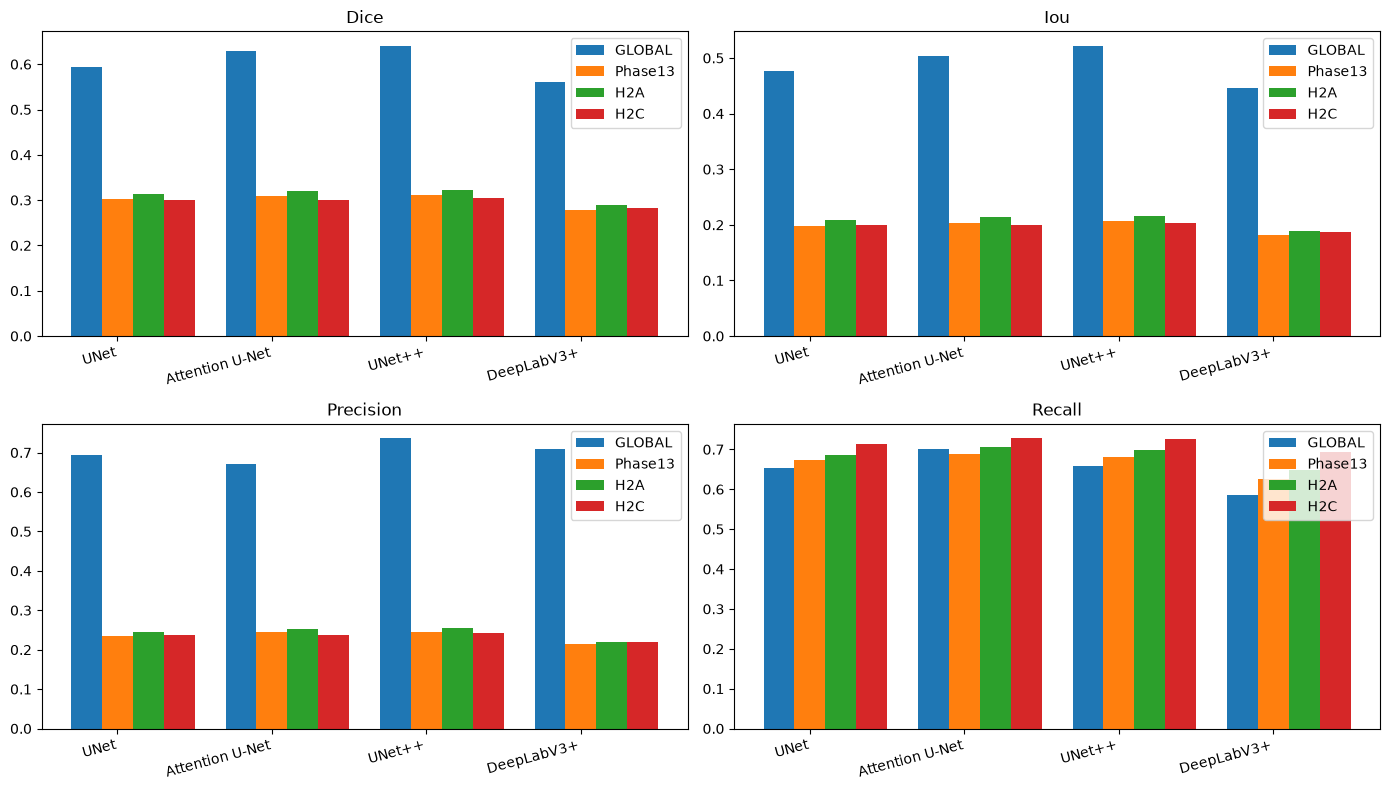

In [7]:

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, m in zip(axes.flat, ["dice", "iou", "precision", "recall"]):
    x = np.arange(len(summary)); w = 0.2
    ax.bar(x - w, summary[f"global_macro_{m}"], w, label="GLOBAL")
    ax.bar(x, summary[f"phase13_predicted_macro_{m}"], w, label="Phase13")
    ax.bar(x + w, summary[f"h2a_predicted_macro_{m}"], w, label="H2A")
    ax.bar(x + 2*w, summary[f"h2c_predicted_macro_{m}"], w, label="H2C")
    ax.set_xticks(x); ax.set_xticklabels(summary["model_display"], rotation=15, ha="right")
    ax.set_title(m.capitalize()); ax.legend()
plt.tight_layout(); plt.show()


## 9. FP / FN

In [8]:

print(summary[["model_display", "mean_global_fp", "mean_h2c_fp", "fp_delta_vs_global",
               "mean_global_fn", "mean_h2c_fn"]].to_string(index=False))


  model_display  mean_global_fp  mean_h2c_fp  fp_delta_vs_global  mean_global_fn  mean_h2c_fn
           UNet     1297.252427 10809.456311         9512.203883     2561.621359  2385.825243
Attention U-Net     1377.194175 11276.514563         9899.320388     2428.135922  2371.281553
         UNet++      888.679612 11220.970874        10332.291262     2569.378641  2269.951456
     DeepLabV3+     1081.563107 11594.786408        10513.223301     2684.252427  2205.407767


## 10. Component Recoveries / Losses

In [9]:

cols = ["model_display", "component_recoveries_vs_global", "component_losses_vs_global",
        "component_recoveries_vs_h2a", "component_losses_vs_h2a"]
print(summary[cols].to_string(index=False))
print()
print(cross.to_string(index=False))


  model_display  component_recoveries_vs_global  component_losses_vs_global  component_recoveries_vs_h2a  component_losses_vs_h2a
           UNet                              19                           0                            3                        1
Attention U-Net                              12                           0                            2                        1
         UNet++                              15                           0                            2                        1
     DeepLabV3+                              22                           0                            7                        1

                                    Unnamed: 0  value
             cases_h2c_improved_vs_global_all4      3
             cases_h2c_nonworse_vs_global_all4      3
                cases_h2c_worse_vs_global_all4     82
            cases_h2c_improved_vs_phase13_all4     44
               cases_h2c_worse_vs_phase13_all4     36
components_recovered_vs_g

## 11. Size Strata

In [10]:

st = comp.groupby(["model", "size_stratum"]).agg(
    n=("native_component_id", "count"), global_detected=("global_detected", "sum"),
    h2c_detected=("h2c_predicted_detected", "sum"), h2a_detected=("h2a_predicted_detected", "sum"),
    recoveries=("GLOBAL_TO_H2C_RECOVERY", "sum"), losses=("GLOBAL_TO_H2C_LOSS", "sum")).reset_index()
print(st.to_string(index=False))


         model size_stratum  n  global_detected  h2c_detected  h2a_detected  recoveries  losses
attention_unet        LARGE 16               15            15            15           0       0
attention_unet       MEDIUM 36               32            34            35           2       0
attention_unet        SMALL 28               24            27            26           3       0
attention_unet         TINY 72               56            63            62           7       0
 deeplabv3plus        LARGE 16               14            15            15           1       0
 deeplabv3plus       MEDIUM 36               30            34            34           4       0
 deeplabv3plus        SMALL 28               23            27            26           4       0
 deeplabv3plus         TINY 72               47            60            55          13       0
          unet        LARGE 16               14            15            15           1       0
          unet       MEDIUM 36          

## 12. Frozen Difficult Cohorts

Global-empty is reported as `GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES`.


In [11]:

ht = comp[comp["hard_tiny"]].groupby("model").agg(n=("native_component_id", "count"),
      global_detected=("global_detected", "sum"), h2c_detected=("h2c_predicted_detected", "sum"),
      recoveries=("GLOBAL_TO_H2C_RECOVERY", "sum"), losses=("GLOBAL_TO_H2C_LOSS", "sum"))
ge = comp[comp["global_empty_image"]].groupby("model").agg(n=("native_component_id", "count"),
      global_detected=("global_detected", "sum"), h2c_detected=("h2c_predicted_detected", "sum"),
      recoveries=("GLOBAL_TO_H2C_RECOVERY", "sum"), losses=("GLOBAL_TO_H2C_LOSS", "sum"))
mc = comp[comp["multi_component_image"]].groupby("model").agg(n=("native_component_id", "count"),
      global_detected=("global_detected", "sum"), h2c_detected=("h2c_predicted_detected", "sum"),
      recoveries=("GLOBAL_TO_H2C_RECOVERY", "sum"), losses=("GLOBAL_TO_H2C_LOSS", "sum"))
print("--- hard_tiny ---"); print(ht)
print("--- GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES ---"); print(ge)
print("--- multi_component ---"); print(mc)


--- hard_tiny ---
                 n  global_detected  h2c_detected  recoveries  losses
model                                                                
attention_unet  15                3             8           5       0
deeplabv3plus   15                2             7           5       0
unet            15                0             7           7       0
unetpp          15                0             7           7       0
--- GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES ---
                n  global_detected  h2c_detected  recoveries  losses
model                                                               
attention_unet  8                1             5           4       0
deeplabv3plus   8                2             4           2       0
unet            8                0             4           4       0
unetpp          8                0             3           3       0
--- multi_component ---
                 n  global_detected  h2c_detected  recoveries  losses

## 13. Localizer → Downstream Translation

In [12]:

pd.set_option("display.max_columns", None); pd.set_option("display.width", 0)
print(link.to_string(index=False))


         model   model_display  h2c_proposal_count  h2c_pixel_any_hit_precision  h2c_bbox_any_hit_precision  h2c_tiny90  h2c_overall90  h2c_overall50  h2c_any_overlap  h2c_mean_coverage  h2c_mean_union_area  h2c_score_max  h2c_score_iqr  h2c_fraction_at_max  h2c_roc_auc  h2c_pr_auc  h2a_proposal_count  h2a_pixel_any_hit_precision  h2a_bbox_any_hit_precision  h2a_tiny90  h2a_overall90  h2a_overall50  h2a_any_overlap  h2a_mean_coverage  h2a_mean_union_area  h2a_score_max  h2a_score_iqr  h2a_fraction_at_max  h2a_roc_auc  h2a_pr_auc  phase13_proposal_count  phase13_pixel_any_hit_precision  phase13_bbox_any_hit_precision  phase13_tiny90  phase13_overall90  phase13_overall50  phase13_any_overlap  phase13_mean_coverage  phase13_mean_union_area  phase13_score_max  phase13_score_iqr  phase13_fraction_at_max  h2c_macro_dice  h2c_macro_iou  h2c_macro_precision  h2c_macro_recall  h2c_mean_fp  h2c_mean_fn  h2c_component_recoveries_vs_global  h2c_component_losses_vs_global  h2a_macro_dice  h2a_macro

## 14. Adjudication (frozen rule applied)

**No criterion was created after observing results.** The frozen H2C outcome definitions from the
H2C protocol were applied verbatim.


In [13]:

print("OUTCOME:", adj["h2c_outcome"])
print("frozen rule source:", adj["frozen_rule_source"])
print("clause applied:", adj["outcome_clause_applied"])
print()
print("reasoning:", adj["reasoning"])
print()
print("--- countervailing evidence (disclosed) ---")
print(adj["countervailing_evidence_disclosed"]["note"])
print()
print("Phase-14 eligibility:", adj["phase14_eligibility"]["status"])


OUTCOME: H2C_HEAD_REDESIGN_INSUFFICIENT
frozen rule source: reports/audits/post_phase13_h2c_protocol_frozen.json :: prospective_outcome_definitions
clause applied: H2C_HEAD_REDESIGN_INSUFFICIENT clause (b): 'favourable localizer changes do not translate into meaningful downstream improvement and the major deployable failure remains'.

reasoning: The localizer changes ARE reproducibly favourable vs H2A (8/10 metrics, including the targeted saturation/dispersion metrics), so clause (a) does not apply. However the frozen PARTIAL definition additionally requires 'at least some corresponding downstream improvement', measured against the protocol-designated PRIMARY downstream comparator (H2A predicted-region). H2C macro Dice is BELOW H2A on ALL FOUR architectures (-0.013550, -0.019084, -0.019004, -0.006560), so the favourable localizer changes did NOT translate into downstream improvement against the primary comparator. The major deployable failure also remains (H2C is far below GLOBAL on al

## 15. B2 Counters

In [14]:

ex = json.loads((AUDITS / "post_phase13_h2c_b2_execution_audit.json").read_text("utf-8"))
for k, v in ex["counters"].items():
    print(f"  {k}: {v}")
print()
for k, v in ex["counter_explanations"].items():
    print(f"  [{k}] {v}")


  logical_training_experiments: 1
  h2c_training_experiments: 1
  proposal_configurations: 1
  proposal_grid: 0
  threshold_searches: 0
  oracle_reruns: 0
  downstream_segmentation_model_constructions: 4
  downstream_segmentation_forwards: 1848
  checkpoint_candidates_evaluated_downstream: 1
  validation_reads: 103 VAL cases
  test_reads: 0
  external_test_reads: 0

  [downstream_segmentation_model_constructions] 4 frozen architectures loaded (0 trained)
  [downstream_segmentation_forwards] 462 proposals x 4 architectures = 1848 regional crops
  [checkpoint_candidates_evaluated_downstream] exactly 1 (H2C epoch 57 best.pt)


## 16. Limitations

1. Single-seed adaptive VAL-development evidence.
2. H2C localizer train/val losses are not comparable in scale to H2A's (frozen zero-terminal
   initialization; identical initial logits and initial loss 19.119539).
3. The H2C-B1 runner's inherited audit-payload identity strings were corrected additively; the
   checkpoint was always correct. The checkpoint records the pre-correction runner SHA.
4. Descriptive comparison only — no winner, no superiority claim, no significance testing.
5. No threshold search, no proposal grid, no head-family/hidden-width search.
6. TEST remains untouched.


## 17. Explicit Phase-14 Stop Boundary

**H2C-B2 does not start Phase 14.**

Phase 14 is ELIGIBLE_NOT_STARTED and requires separate supervisor authorization.


## 18. Artifact SHA Registry

In [15]:

artifacts = [
    "reports/audits/post_phase13_h2c_protocol_frozen.json",
    "reports/audits/post_phase13_h2c_b1_training_evaluation.json",
    "reports/audits/post_phase13_h2c_b1_audit_identity_correction.json",
    "reports/audits/post_phase13_h2c_b2_freeze_manifest.json",
    "reports/audits/post_phase13_h2c_b2_downstream_integrity.json",
    "reports/audits/post_phase13_h2c_b2_outcome_adjudication.json",
    "reports/audits/post_phase13_h2c_b2_execution_audit.json",
    "reports/audits/post_h2c_chain_closure_report.json",
    "reports/tables/post_phase13_h2c_downstream_case_model_metrics.csv",
    "reports/tables/post_phase13_h2c_downstream_component_model_metrics.csv",
    "reports/tables/post_phase13_h2c_downstream_model_summary.csv",
    "reports/tables/post_phase13_h2c_downstream_cross_architecture_summary.csv",
    "reports/tables/post_phase13_h2c_localizer_to_downstream_comparison.csv",
    "reports/tables/post_phase13_h2c_vs_h2a_vs_phase13_localizer_comparison.csv",
    "checkpoints/" + EID + "/best.pt",
]
for a in artifacts:
    p = ROOT / a
    print(f"{sha(p) if p.exists() else 'MISSING':64s}  {Path(a).name}")


91166259c10a84e9526eda43e83b227cc760a37b8834a4d4a65fe3e5a90ba4b6  post_phase13_h2c_protocol_frozen.json
ae20f39de080d60f59fbfef93ff42bc0fdebf9f4410149440b06873f1c6f975b  post_phase13_h2c_b1_training_evaluation.json
19b40c50ffdd02f2c6f77af794093669cf0de05254c0af899bd60366adaad5b3  post_phase13_h2c_b1_audit_identity_correction.json
3efb739df79f67a5782c7655ecd0fbf474ce8a772343310727a3d2ae5335d92d  post_phase13_h2c_b2_freeze_manifest.json
8aad74d04ba0373dc60a7433ae953c7ceab04cd93f332b5c55886413221e15ec  post_phase13_h2c_b2_downstream_integrity.json
b1d19ba8032520d98f3f2b25132795142c9bb4f98e565d9431b1795c23fe48fe  post_phase13_h2c_b2_outcome_adjudication.json
b291f7225dc9d132246a39c04586945e464c0de6bd5e9252434515c4a66a3974  post_phase13_h2c_b2_execution_audit.json
22b1c49b5f688608d4be4e8077a95c1f67d22832c0ba8c3ae1a972b9d00555f7  post_h2c_chain_closure_report.json
b95041f4cd259acbeb77dd731d93ed930d284e34208adf2f6845f60b0ac304d3  post_phase13_h2c_downstream_case_model_metrics.csv
35b2b718325e

## 19. Mandatory Complete Tables (Untruncated)


In [16]:

_pd = pd
_pd.set_option("display.max_rows", None); _pd.set_option("display.max_columns", None)
_pd.set_option("display.width", 0); _pd.set_option("display.max_colwidth", None)
print("=" * 100); print(f"MODEL SUMMARY — {len(summary)} / 4 rows"); print("=" * 100)
print(summary.to_string(index=False)); print()
assert len(summary) == 4


MODEL SUMMARY — 4 / 4 rows
         model   model_display  proposal_count  mean_proposals_per_image  mean_intervention_union_area  global_macro_dice  phase13_predicted_macro_dice  h2c_predicted_macro_dice  oracle_macro_dice  DELTA_H2C_GLOBAL_DICE  DELTA_H2C_PHASE13_DICE  h2a_predicted_macro_dice  h2a_predicted_macro_iou  h2a_predicted_macro_precision  h2a_predicted_macro_recall  mean_h2a_fp  mean_h2a_fn  DELTA_H2C_H2A_DICE  ORACLE_GAIN_FROM_GLOBAL  H2C_ORACLE_BENEFIT_RETENTION  H2C_ORACLE_GAP  global_macro_iou  phase13_predicted_macro_iou  h2c_predicted_macro_iou  oracle_macro_iou  global_macro_precision  phase13_predicted_macro_precision  h2c_predicted_macro_precision  oracle_macro_precision  global_macro_recall  phase13_predicted_macro_recall  h2c_predicted_macro_recall  oracle_macro_recall  mean_global_fp  mean_phase13_fp  mean_h2c_fp  mean_oracle_fp  mean_global_fn  mean_phase13_fn  mean_h2c_fn  mean_oracle_fn  fp_delta_vs_global  fp_delta_vs_phase13  fn_delta_vs_global  fn_delta_v

In [17]:

print("=" * 100); print(f"CASE-MODEL METRICS — {len(case)} / 412 rows"); print("=" * 100)
print(case.to_string(index=False)); print()
assert len(case) == 412
print(f"CONFIRMED: {len(case)} rows | {case['sample_id'].nunique()} cases | {case['model'].nunique()} models")


CASE-MODEL METRICS — 412 / 412 rows
                       sample_id          model   model_display  native_height  native_width  native_gt_components  h2c_proposal_count  h2c_proposal_union_area_fraction  hard_tiny_image  global_empty_image  multi_component_image  h2c_proposal_score_mean  h2c_proposal_score_max  global_dice   global_iou  global_precision  global_recall  global_tp_pixels  global_fp_pixels  global_fn_pixels  global_prediction_empty  global_hd95  global_hd95_valid global_hd95_invalid_reason  global_detected_native_components  global_missed_native_components  global_object_recall  oracle_dice  oracle_iou  oracle_precision  oracle_recall  oracle_tp_pixels  oracle_fp_pixels  oracle_fn_pixels  oracle_prediction_empty  oracle_hd95  oracle_hd95_valid  oracle_hd95_invalid_reason  oracle_detected_native_components  oracle_missed_native_components  oracle_object_recall  phase13_predicted_dice  phase13_predicted_iou  phase13_predicted_precision  phase13_predicted_recall  phase13_p

In [18]:

print("=" * 100); print(f"COMPONENT-MODEL METRICS — {len(comp)} / 608 rows"); print("=" * 100)
print(comp.to_string(index=False)); print()
assert len(comp) == 608
print(f"CONFIRMED: {len(comp)} rows | {comp['model'].nunique()} models")


COMPONENT-MODEL METRICS — 608 / 608 rows
                       sample_id  native_component_id          model   model_display size_stratum  component_pixels  hard_tiny  global_empty_image  multi_component_image  h2c_coverage_fraction  h2c_covered90  h2c_covered50  h2c_any_overlap  global_detected  oracle_detected  phase13_predicted_detected  h2c_predicted_detected  GLOBAL_TO_H2C_RECOVERY  GLOBAL_TO_H2C_LOSS  PHASE13_TO_H2C_RECOVERY  PHASE13_TO_H2C_LOSS  h2a_predicted_detected  H2A_TO_H2C_RECOVERY  H2A_TO_H2C_LOSS
66b947d8ead11ae1260bc3142ca1707d                    1           unet            UNet         TINY               522      False               False                  False               0.967742           True           True             True            False             True                        True                    True                    True               False                    False                False                    True                False            False
66b